# Задание 3. Кластерный анализ стран-партнёров — в логике SPSS

Анализ повторяет стандартный сценарий SPSS **Analyze → Classify → Hierarchical Cluster**:

| Шаг SPSS | Что делаем здесь |
|---|---|
| Data View / Variable View | показываем матрицу данных, переменные, описательные статистики |
| Transform values: **Z scores** by variable | стандартизация переменных (σ с делителем n−1, как в SPSS) |
| Measure: **Squared Euclidean distance** | матрица расстояний (Proximity Matrix) |
| Method: **Ward's method** | иерархическое объединение |
| Statistics: **Agglomeration schedule** | таблица агломерации (стадии, коэффициенты) |
| Plots: **Dendrogram** | дендрограмма на шкале Rescaled Distance 0–25 |
| Statistics: **Cluster membership** (range of solutions) | принадлежность стран для 2…8 кластеров |
| Compare Means / One-Way ANOVA | профиль кластеров |
| K-Means Cluster (проверка) | дополнительная проверка разбиения |

**Предупреждение о данных.** В файлах Белстата из Задания 1 нет разбивки по странам, поэтому матрица **синтетическая**:
10 товарных групп — реальные (из позиций Задания 1), 66 стран и их профили — сгенерированы (см. `src/synthetic.py`).
Результаты описывают метод, а не реальную торговлю Беларуси.

In [1]:
import os
import sys
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import pyogrio.raw as pgraw
import pyreadstat
import seaborn as sns
import shapely
from adjustText import adjust_text
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon
from scipy import stats
from scipy.cluster.hierarchy import cut_tree, dendrogram, linkage
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, silhouette_samples, silhouette_score)

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from synthetic import GROUP_MAP, GROUPS, load_matrix  # noqa: E402

FIG, RES, DATA, SPSS = ROOT / "figures", ROOT / "results", ROOT / "data", ROOT / "spss"
for d in (FIG, RES, SPSS):
    d.mkdir(exist_ok=True)
SEED = 42
sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight", "axes.titleweight": "bold",
                     "axes.titlesize": 11, "axes.spines.top": False, "axes.spines.right": False})
PALETTE = ["#1f77b4", "#e8710a", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#17becf", "#bcbd22", "#7f7f7f"]
SRC = "Данные синтетические (см. README); расчёты автора"
SHORT = {"Металлы и металлоизделия": "Металлы", "Машины и транспорт": "Машины/транспорт", "Автозапчасти": "Автозапчасти",
         "Электроника и электротехника": "Электроника", "Химия и пластмассы": "Химия/пластик", "Молочная продукция": "Молочка",
         "Мясо": "Мясо", "Сахар, масла и корма": "Сахар/масла/корма", "Древесина и мебель": "Древесина/мебель",
         "Фармацевтика": "Фармацевтика"}
# латинские имена переменных для SPSS
VAR = dict(zip(GROUPS, ["Metals", "Machinery", "AutoParts", "Electronics", "Chemicals", "Dairy", "Meat", "SugarOilFeed",
                        "WoodFurniture", "Pharma"]))


def save(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()

## Шаг 1. Данные: что и как загружается

### 1.1. Исходный вид: длинная таблица «страна — товарная группа — значение торговли»
Так выглядят данные «на входе» (каждая строка = страна × группа, значение в условных единицах). Реальный файл по странам должен иметь тот же формат.

In [2]:
raw, IS_SYNTH = load_matrix(os.environ.get("TRADE_CSV"), seed=SEED, kappa=60)
HAS_TRUTH = "true_archetype" in raw.columns
long = raw.melt(id_vars=["iso3", "country"], value_vars=GROUPS, var_name="group", value_name="value")
print("Длинный формат (первые 8 строк из %d):" % len(long))
print(long.head(8).round(2).to_string(index=False))

Длинный формат (первые 8 строк из 660):
iso3     country                    group  value
 RUS      Россия Металлы и металлоизделия  51.60
 KAZ   Казахстан Металлы и металлоизделия   2.12
 KGZ    Киргизия Металлы и металлоизделия   0.76
 ARM     Армения Металлы и металлоизделия   0.20
 UZB  Узбекистан Металлы и металлоизделия   2.28
 AZE Азербайджан Металлы и металлоизделия   0.32
 MDA     Молдова Металлы и металлоизделия   0.20
 TJK Таджикистан Металлы и металлоизделия   0.16


### 1.2. Превращаем в матрицу «страны × переменные» (Data View в SPSS)
- **Строки (cases)** — страны, **столбцы (variables)** — 10 товарных групп.
- Значение переменной = **доля группы в торговле со страной, %** (сумма по строке = 100%). Так сравнивается *структура* торговли, а не её объём.
- Объём торговли (`Volume`) хранится отдельно и в кластеризации **не участвует**.

In [3]:
P = raw[GROUPS].div(raw[GROUPS].sum(axis=1), axis=0) * 100
P.columns = [VAR[g] for g in GROUPS]
DV = pd.DataFrame({"Case": np.arange(1, len(raw) + 1), "Country": raw["country"].to_numpy(), "ISO3": raw["iso3"].to_numpy(),
                   "Volume": raw["volume"].to_numpy(), **{c: P[c].to_numpy() for c in P.columns}})
assert np.allclose(DV[list(VAR.values())].sum(axis=1), 100)
DV.to_csv(DATA / "trade_shares.csv", index=False, encoding="utf-8-sig")
DV.to_csv(RES / "01_data_view.csv", index=False, encoding="utf-8-sig")
pd.set_option("display.width", 250, "display.max_columns", 30)
print("DATA VIEW — матрица данных, 66 строк × 10 переменных (первые 15 строк; полностью в results/01_data_view.csv):\n")
print(DV.drop(columns="Volume").head(15).round(1).to_string(index=False))

DATA VIEW — матрица данных, 66 строк × 10 переменных (первые 15 строк; полностью в results/01_data_view.csv):

 Case     Country ISO3  Metals  Machinery  AutoParts  Electronics  Chemicals  Dairy  Meat  SugarOilFeed  WoodFurniture  Pharma
    1      Россия  RUS     9.4       15.1       11.7          6.9        6.8   12.4  10.6           3.7           12.7    10.6
    2   Казахстан  KAZ     7.4       13.2        7.3          3.4        2.5   22.8  16.7           2.5            7.3    16.9
    3    Киргизия  KGZ    17.1       14.4        7.2          6.3        9.9    9.9   7.2           2.7            5.4    19.8
    4     Армения  ARM     7.4       19.1       11.8          7.4        2.9    7.4  20.6           8.8            2.9    11.8
    5  Узбекистан  UZB    13.7       21.1        5.0          4.1        1.9   13.7  14.6           5.3            9.4    11.3
    6 Азербайджан  AZE     4.8       25.0       10.7         10.7        2.4   11.9   4.2           4.2           10.7    15.5


### 1.3. Variable View: переменные
Тип — Numeric, шкала измерения — **Scale**, единица — %. Метки — на русском (сохраняются и в `.sav`).

In [4]:
var_view = pd.DataFrame({
    "Name": list(VAR.values()), "Label (описание)": [f"Доля: {g}, %" for g in GROUPS], "Type": "Numeric", "Measure": "Scale",
    "Состав (позиции Задания 1)": [", ".join(GROUP_MAP[g]) for g in GROUPS]})
var_view.to_csv(RES / "02_variable_view.csv", index=False, encoding="utf-8-sig")
print(var_view.to_string(index=False))

# экспорт в формат SPSS
labels = ["Номер случая", "Страна", "Код ISO3", "Объём торговли (усл. ед.; в кластеризации не участвует)"] + [f"Доля: {g}, %" for g in GROUPS]
pyreadstat.write_sav(DV, str(DATA / "trade_shares.sav"), column_labels=labels,
                     variable_measure={c: ("scale" if c not in ("Country", "ISO3") else "nominal") for c in DV.columns})
print("\nСохранён файл для SPSS: data/trade_shares.sav")

         Name                      Label (описание)    Type Measure                                             Состав (позиции Задания 1)
       Metals     Доля: Металлы и металлоизделия, % Numeric   Scale                     Чёрные металлы, Стальные трубы, Металлоконструкции
    Machinery           Доля: Машины и транспорт, % Numeric   Scale                   Легковые авто, С/х техника, Двигатели ВС, Спецмашины
    AutoParts                 Доля: Автозапчасти, % Numeric   Scale                                                           Автозапчасти
  Electronics Доля: Электроника и электротехника, % Numeric   Scale           Компьютеры, Аппаратура связи, Холодильники, Провода и кабели
    Chemicals           Доля: Химия и пластмассы, % Numeric   Scale              Хим. волокна и нити, Синтетич. каучук, Пластмассовая тара
        Dairy           Доля: Молочная продукция, % Numeric   Scale Молоко (несгущ.), Молоко (сгущ./сухое), Масло сливочное, Сыры и творог
         Meat              

### 1.4. Case Processing Summary и Descriptives

In [5]:
n, p = len(DV), len(VAR)
print(f"Case Processing Summary: valid N = {n} ({n / n:.0%}), missing = 0, всего = {n}")
desc = DV[list(VAR.values())].agg(["count", "min", "max", "mean", "std"]).T
desc.columns = ["N", "Minimum", "Maximum", "Mean", "Std. Deviation"]
desc["Нулей"] = (DV[list(VAR.values())] == 0).sum()
desc.to_csv(RES / "03_descriptives.csv", encoding="utf-8-sig")
print(desc.round(2).to_string())

Case Processing Summary: valid N = 66 (100%), missing = 0, всего = 66
                  N  Minimum  Maximum   Mean  Std. Deviation  Нулей
Metals         66.0     0.00    47.50  10.62           10.32      1
Machinery      66.0     0.00    35.77  11.42            8.26      1
AutoParts      66.0     0.00    19.92   6.25            4.83      6
Electronics    66.0     0.00    36.41   8.35            9.23      6
Chemicals      66.0     0.00    27.80   9.27            6.02      1
Dairy          66.0     0.00    42.08   9.69            9.64      2
Meat           66.0     0.00    41.95  10.58           12.29      3
SugarOilFeed   66.0     0.26    75.22  13.26           19.57      0
WoodFurniture  66.0     0.00    40.15  10.89           12.84      5
Pharma         66.0     1.92    21.92   9.67            4.85      0


**Читаем:** пропусков нет (N = 66). Средняя доля каждой группы ≈ 6–13% (при 10 группах), но разброс очень велик: например, у «Сахара, масел и кормов» от 0,3% до 75% при среднем 13%.
Нулевых значений 25 из 660 (у малых стран, чаще всего в автозапчастях и электронике — по 6) — стандартизация и квадрат евклидова расстояния с нулями проблем не создают.

### 1.5. Проверка данных: корреляции переменных и выбросы
Доли в сумме дают 100%, поэтому они слегка отрицательно связаны между собой (структурная «замкнутость»). Для иерархического метода Уорда это допустимо,
но стоит помнить: одна переменная избыточна, а группы-антагонисты (мясо и молочка с одной стороны, электроника с другой) задают основные оси различий.

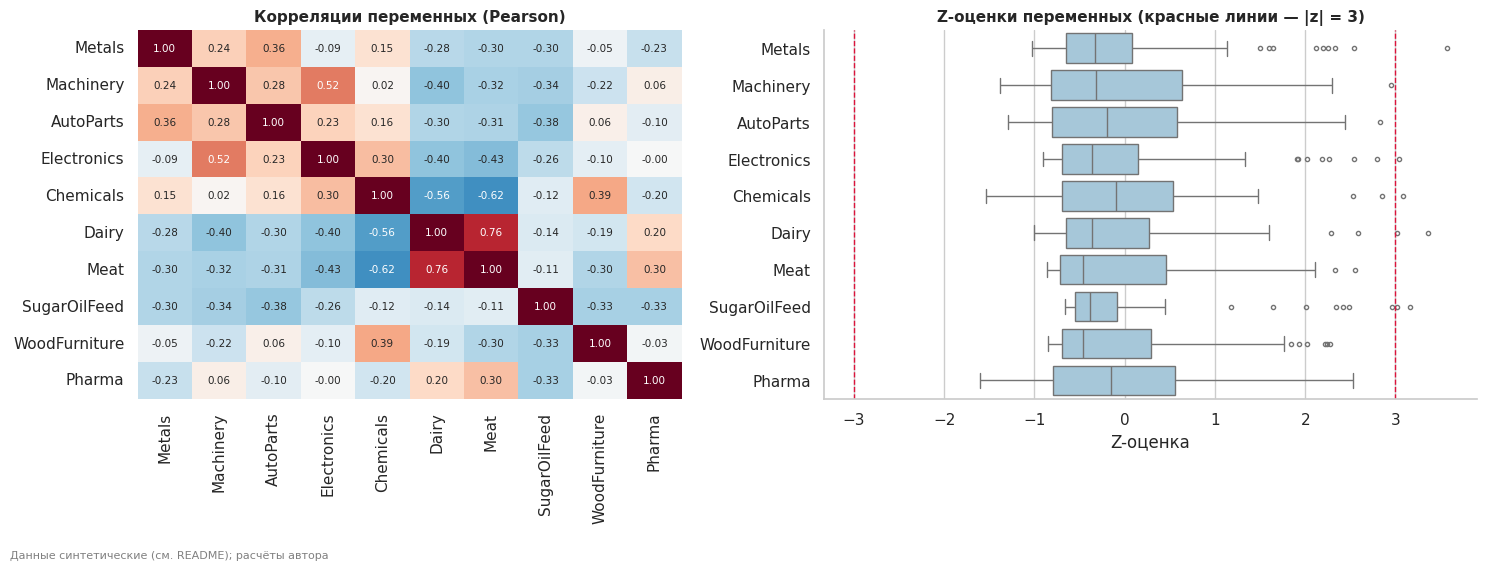

Выбросы по |z| > 3: {'Metals': 1, 'Electronics': 1, 'Chemicals': 1, 'Dairy': 2, 'SugarOilFeed': 2}
Самые сильные корреляции:
 Dairy        Meat           0.76
Chemicals    Meat          -0.62
             Dairy         -0.56
Machinery    Electronics    0.52
Electronics  Meat          -0.43


In [6]:
Zdf = (DV[list(VAR.values())] - DV[list(VAR.values())].mean()) / DV[list(VAR.values())].std(ddof=1)  # Z-scores, как в SPSS (n−1)
corr = DV[list(VAR.values())].corr()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.2]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0], cbar=False, annot_kws={"fontsize": 7.5})
axes[0].set_title("Корреляции переменных (Pearson)")
sns.boxplot(data=Zdf.melt(var_name="v", value_name="z"), x="z", y="v", ax=axes[1], color="#9ecae1", fliersize=3)
axes[1].axvline(3, color="crimson", ls="--", lw=1)
axes[1].axvline(-3, color="crimson", ls="--", lw=1)
axes[1].set_title("Z-оценки переменных (красные линии — |z| = 3)")
axes[1].set_xlabel("Z-оценка")
axes[1].set_ylabel("")
fig.text(0.01, -0.03, SRC, fontsize=8, color="grey")
fig.tight_layout()
save(fig, "fig01_data_check")
out = (Zdf.abs() > 3).sum()
print("Выбросы по |z| > 3:", out[out > 0].to_dict() or "нет")
print("Самые сильные корреляции:\n", corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(key=abs, ascending=False).head(5).round(2).to_string())

**Читаем:** корреляции умеренные, максимум |r| = 0,76. Молочка и мясо связаны положительно (0,76) — вместе они образуют «продовольственную» ось; химия отрицательно связана с мясом (−0,62) и молочкой (−0,56);
машины и электроника положительно (0,52). Мультиколлинеарности, которая разрушила бы метод, нет.
Выбросов (|z| > 3) всего 7 наблюдений в пяти переменных (сахар/масла/корма и молочка — по 2, металлы, электроника, химия — по 1): это страны с экстремальной специализацией
(до 75% торговли в одной группе). Это не ошибки данных, а именно те различия, которые должен ловить кластерный анализ, поэтому выбросы не удаляются.

## Шаг 2. Z-оценки и матрица расстояний (Proximity Matrix)
Метод Уорда чувствителен к масштабу, поэтому каждая переменная приводится к Z-оценке (среднее 0, σ = 1, делитель n−1 — как в SPSS **Transform values → Z scores**).
Расстояние — **квадрат евклидова** (Squared Euclidean distance).

In [7]:
Z = Zdf.to_numpy()
names = DV["Country"].to_numpy()
iso = DV["ISO3"].to_numpy()
print("Среднее Z ≈", Z.mean().round(10), "| σ(n−1) =", Z.std(axis=0, ddof=1).round(3))
Dm = squareform(pdist(Z, "sqeuclidean"))
pd.DataFrame(Dm, index=names, columns=names).round(3).to_csv(RES / "04_proximity_matrix_sqeuclid.csv", encoding="utf-8-sig")
print("\nProximity Matrix (квадрат евклидова расстояния), фрагмент 6×6 (полностью в results/04_proximity_matrix_sqeuclid.csv):")
print(pd.DataFrame(Dm[:6, :6], index=names[:6], columns=names[:6]).round(1).to_string())
iu = np.triu_indices(n, 1)
pairs = pd.DataFrame({"A": names[iu[0]], "B": names[iu[1]], "d2": Dm[iu]}).sort_values("d2")
print("\nСамые близкие пары (наиболее похожая структура торговли):\n", pairs.head(5).round(2).to_string(index=False))
print("\nСамые далёкие пары:\n", pairs.tail(5).round(2).to_string(index=False))

Среднее Z ≈ -0.0 | σ(n−1) = [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Proximity Matrix (квадрат евклидова расстояния), фрагмент 6×6 (полностью в results/04_proximity_matrix_sqeuclid.csv):
             Россия  Казахстан  Киргизия  Армения  Узбекистан  Азербайджан
Россия          0.0        4.8       5.8      2.3         3.6          3.7
Казахстан       4.8        0.0       5.3      5.5         3.8          5.7
Киргизия        5.8        5.3       0.0      7.6         6.5          6.5
Армения         2.3        5.5       7.6      0.0         3.5          3.8
Узбекистан      3.6        3.8       6.5      3.5         0.0          4.4
Азербайджан     3.7        5.7       6.5      3.8         4.4          0.0

Самые близкие пары (наиболее похожая структура торговли):
       A       B   d2
  Дания Австрия 0.69
   Иран Марокко 0.80
    ОАЭ    Оман 0.94
  Китай Вьетнам 0.97
Эстония Франция 1.02

Самые далёкие пары:
      A        B    d2
  Иран Малайзия 50.92
  Иран  Тайвань 52.27
Швеция     Иран 53.87


## Шаг 3. Иерархическая кластеризация методом Уорда: Agglomeration Schedule
На каждом шаге объединяются два кластера, дающие **наименьший прирост внутригрупповой суммы квадратов** (SSE). Коэффициент в таблице агломерации SPSS для метода Уорда —
накопленная внутригрупповая сумма квадратов; прирост коэффициента показывает, «насколько дорого» очередное объединение.
Контроль: после последнего шага накопленный коэффициент должен равняться полной сумме квадратов Z-оценок = (n−1)·p = 65·10 = 650.

In [8]:
L = linkage(Z, "ward")
inc = L[:, 2] ** 2 / 2  # прирост SSE на каждой стадии (для Уорда: высота² = 2·ΔSSE)
cum = np.cumsum(inc)
print(f"Контроль: накопленный коэффициент на последней стадии = {cum[-1]:.3f}; (n−1)·p = {(n - 1) * p}")
assert np.isclose(cum[-1], (n - 1) * p)

min_case = {i: i + 1 for i in range(n)}  # как в SPSS: кластер обозначается наименьшим номером случая в нём
formed = {i: 0 for i in range(n)}
rows = []
for s, (a, b, h, sz) in enumerate(L, start=1):
    a, b = int(a), int(b)
    ca, cb = min_case[a], min_case[b]
    first, second = (a, b) if ca <= cb else (b, a)
    rows.append(dict(Stage=s, Cluster1=min(ca, cb), Cluster2=max(ca, cb), Coefficients=cum[s - 1], Increment=inc[s - 1],
                     First_appears_1=formed[first], First_appears_2=formed[second], Next_stage=0, _a=a, _b=b))
    new = n + s - 1
    min_case[new] = min(ca, cb)
    formed[new] = s
AGG = pd.DataFrame(rows)
for s in range(1, n):  # Next stage = стадия, где образованный кластер объединяется дальше
    newid = n + s - 1
    nxt = AGG[(AGG["_a"] == newid) | (AGG["_b"] == newid)]["Stage"]
    AGG.loc[AGG.Stage == s, "Next_stage"] = int(nxt.iloc[0]) if len(nxt) else 0
AGG["Clusters_after"] = n - AGG["Stage"]
AGG = AGG.drop(columns=["_a", "_b"])
AGG.to_csv(RES / "05_agglomeration_schedule.csv", index=False, encoding="utf-8-sig")
print("\nAgglomeration Schedule (первые 6 стадий):")
print(AGG.head(6).round(3).to_string(index=False))
print("\nAgglomeration Schedule (последние 14 стадий):")
print(AGG.tail(14).round(2).to_string(index=False))

Контроль: накопленный коэффициент на последней стадии = 650.000; (n−1)·p = 650

Agglomeration Schedule (первые 6 стадий):
 Stage  Cluster1  Cluster2  Coefficients  Increment  First_appears_1  First_appears_2  Next_stage  Clusters_after
     1        19        24         0.345      0.345                0                0          15              65
     2        31        32         0.746      0.401                0                0          39              64
     3        29        35         1.217      0.471                0                0           8              63
     4        39        42         1.700      0.483                0                0          17              62
     5        14        22         2.210      0.510                0                0          37              61
     6        49        51         2.778      0.568                0                0           7              60

Agglomeration Schedule (последние 14 стадий):
 Stage  Cluster1  Cluster2  Coeff

## Шаг 4. Сколько кластеров? Решение по таблице агломерации и дендрограмме
Правило SPSS-практики: **остановиться перед объединением, после которого коэффициент резко растёт** (дендрограмма: ветви, которые «сливаются» далеко от остальных, — разные кластеры).
Измеряем скачок как отношение прироста на стадии к приросту на предыдущей. Если на стадии, где остаётся k кластеров, скачок наибольший — значит, слияние k+1→k «дорогое», и надо оставить k+1 кластеров.

In [9]:
last = AGG.tail(12).copy().reset_index(drop=True)
last["Ratio_to_previous"] = last["Increment"] / AGG["Increment"].shift(1).tail(12).to_numpy()
last["Cost_of_merging_to"] = last["Clusters_after"]  # объединение «k+1 → k»
tab = last[["Clusters_after", "Increment", "Ratio_to_previous"]].rename(columns={"Clusters_after": "after merge: k"})
print("Стоимость объединений (прирост SSE) и скачок относительно предыдущего шага:")
print(tab.round(2).to_string(index=False))
cand = last[(last.Clusters_after >= 2) & (last.Clusters_after <= 8)]
jump_k = int(cand.loc[cand["Ratio_to_previous"].idxmax(), "Clusters_after"])  # k после самого «дорогого» слияния
K_FINAL = jump_k + 1
print(f"\nНаибольший скачок — при слиянии {jump_k + 1} → {jump_k} кластеров (в {cand['Ratio_to_previous'].max():.2f} раза дороже предыдущего шага).")
print(f"=> по таблице агломерации оставляем k = {K_FINAL} кластеров")

# подтверждение внутренними критериями на разрезах дендрограммы
chk = []
for k in range(2, 11):
    lab = cut_tree(L, k).ravel()
    chk.append(dict(k=k, silhouette=silhouette_score(Z, lab), calinski_harabasz=calinski_harabasz_score(Z, lab),
                    min_size=int(np.bincount(lab).min())))
CHK = pd.DataFrame(chk).set_index("k")
CHK.to_csv(RES / "06_cut_validation.csv", encoding="utf-8-sig")
print("\nПроверка разрезов дендрограммы внутренними критериями:")
print(CHK.round(3).to_string())
print(f"Силуэт максимален при k = {CHK.silhouette.idxmax()}, Калински–Харабаз — при k = {CHK.calinski_harabasz.idxmax()}")

Стоимость объединений (прирост SSE) и скачок относительно предыдущего шага:
 after merge: k  Increment  Ratio_to_previous
             12      10.17               1.34
             11      10.89               1.07
             10      11.58               1.06
              9      11.66               1.01
              8      12.49               1.07
              7      14.91               1.19
              6      22.83               1.53
              5      32.88               1.44
              4      56.04               1.70
              3      81.11               1.45
              2     101.04               1.25
              1     166.53               1.65

Наибольший скачок — при слиянии 5 → 4 кластеров (в 1.70 раза дороже предыдущего шага).
=> по таблице агломерации оставляем k = 5 кластеров

Проверка разрезов дендрограммы внутренними критериями:
    silhouette  calinski_harabasz  min_size
k                                          
2        0.264             22.044        1

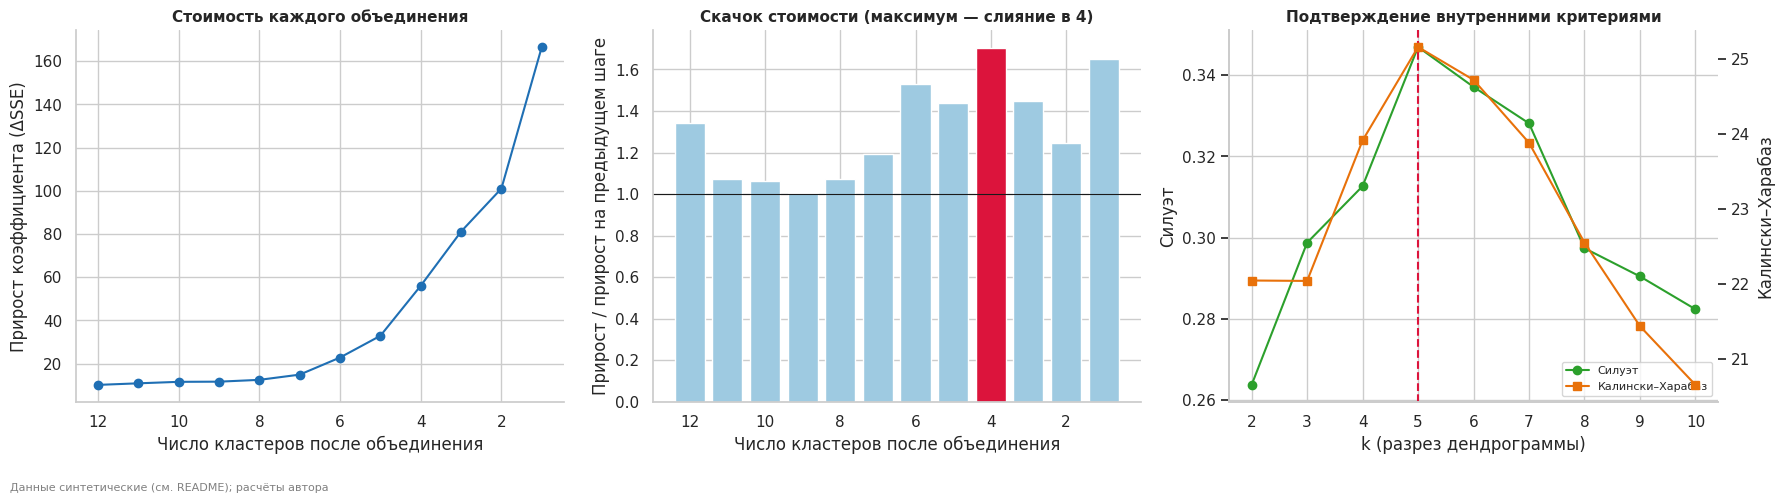

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ks_ = last["Clusters_after"].to_numpy()
axes[0].plot(ks_, last["Increment"], "-o", color="#1f6fb4")
axes[0].invert_xaxis()
axes[0].set_xlabel("Число кластеров после объединения")
axes[0].set_ylabel("Прирост коэффициента (ΔSSE)")
axes[0].set_title("Стоимость каждого объединения")
axes[1].bar(ks_, last["Ratio_to_previous"], color=["crimson" if k == jump_k else "#9ecae1" for k in ks_])
axes[1].invert_xaxis()
axes[1].axhline(1, color="k", lw=0.8)
axes[1].set_xlabel("Число кластеров после объединения")
axes[1].set_ylabel("Прирост / прирост на предыдущем шаге")
axes[1].set_title(f"Скачок стоимости (максимум — слияние в {jump_k})")
axes[2].plot(CHK.index, CHK["silhouette"], "-o", label="Силуэт", color="#2ca02c")
ax2 = axes[2].twinx()
ax2.plot(CHK.index, CHK["calinski_harabasz"], "-s", label="Калински–Харабаз", color="#e8710a")
ax2.grid(False)
axes[2].axvline(K_FINAL, color="crimson", ls="--")
axes[2].set_xlabel("k (разрез дендрограммы)")
axes[2].set_ylabel("Силуэт")
ax2.set_ylabel("Калински–Харабаз")
axes[2].set_title("Подтверждение внутренними критериями")
h1, l1 = axes[2].get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
axes[2].legend(h1 + h2, l1 + l2, loc="lower right", fontsize=8)
fig.text(0.01, -0.04, SRC, fontsize=8, color="grey")
fig.tight_layout()
save(fig, "fig02_agglomeration_decision")

**Читаем:** стоимость объединения плавно растёт от ≈ 12 (при слиянии до 8–9 кластеров) до 22,8 (до 6), 32,9 (до 5), **56,0 (до 4)**, 81,1 (до 3), 101,0 (до 2) и 166,5 (до 1).
Самый резкий относительный скачок — при переходе от 5 к 4 кластерам (×1,70): объединять пятый и четвёртый кластеры «слишком дорого», значит, **оставляем 5 кластеров**.
Силуэт (0,347) и индекс Калински–Харабаза (25,2) также максимальны именно при k = 5. Три независимых признака сходятся на пяти кластерах.
Резкого «излома» здесь нет (структура иерархическая, а не из одного чёткого уровня), поэтому ниже показаны и соседние решения (4–6).

## Шаг 5. Дендрограмма (Rescaled Distance Cluster Combine, шкала 0–25)
Как в SPSS: коэффициенты агломерации масштабируются так, чтобы последнее объединение было на уровне 25. Горизонтальная линия — разрез на выбранном числе кластеров.

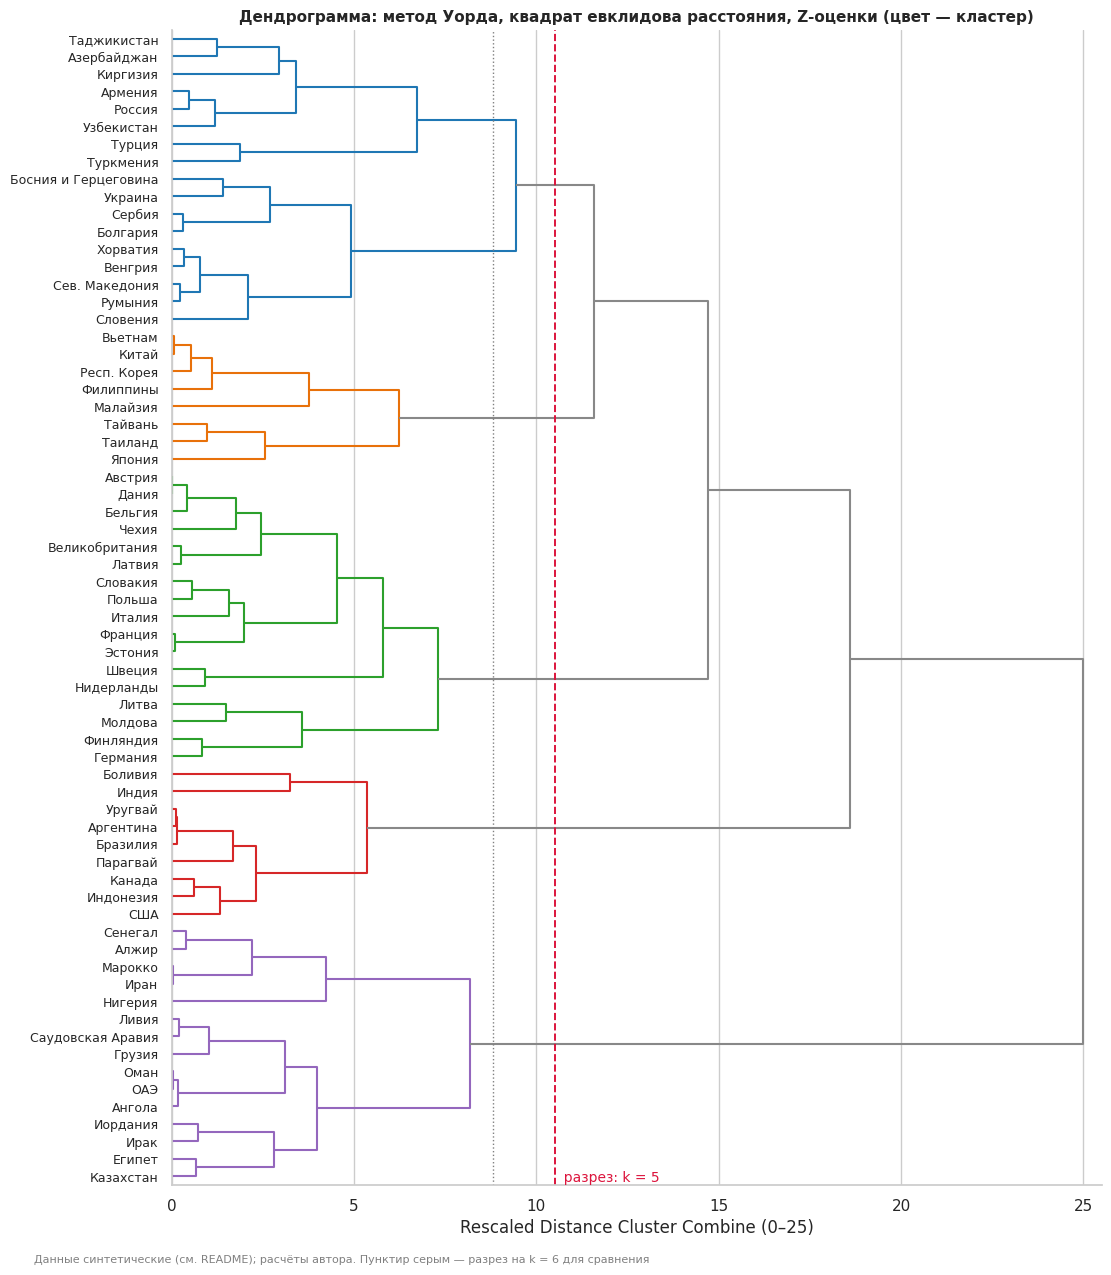

In [11]:
Ls = L.copy()
Ls[:, 2] = cum / cum[-1] * 25  # шкала SPSS: накопленный коэффициент, нормированный на 25
cut_level = (Ls[n - K_FINAL - 1, 2] + Ls[n - K_FINAL, 2]) / 2  # между последним слиянием внутри K кластеров и следующим
cut6 = (Ls[n - 6 - 1, 2] + Ls[n - 6, 2]) / 2

# итоговые метки кластеров: нумерация в порядке появления на дендрограмме (сверху вниз)
leaf_order = dendrogram(Ls, no_plot=True)["leaves"][::-1]  # в горизонтальной дендрограмме первый лист рисуется снизу
lab_raw = cut_tree(L, K_FINAL).ravel()
order_ = list(dict.fromkeys(lab_raw[i] for i in leaf_order))
LAB = np.array([{old: new for new, old in enumerate(order_)}[v] for v in lab_raw])
K = K_FINAL

node_color = {i: PALETTE[LAB[i]] for i in range(n)}
for s_, (a_, b_, h_, _) in enumerate(Ls):
    ca, cb = node_color[int(a_)], node_color[int(b_)]
    node_color[n + s_] = ca if (ca == cb and h_ < cut_level) else "#888888"
fig, ax = plt.subplots(figsize=(12, 15))
dd = dendrogram(Ls, labels=names, orientation="right", link_color_func=lambda k: node_color[k], leaf_font_size=9, ax=ax)
ax.axvline(cut_level, color="crimson", ls="--", lw=1.4)
ax.text(cut_level, ax.get_ylim()[0], f"  разрез: k = {K_FINAL}", color="crimson", fontsize=10, va="bottom")
ax.axvline(cut6, color="grey", ls=":", lw=1)
ax.set_xlabel("Rescaled Distance Cluster Combine (0–25)")
ax.set_xlim(0, 25.5)
ax.set_title("Дендрограмма: метод Уорда, квадрат евклидова расстояния, Z-оценки (цвет — кластер)")
ax.grid(axis="y", visible=False)
fig.text(0.01, 0.058, SRC + ". Пунктир серым — разрез на k = 6 для сравнения", fontsize=8, color="grey")
save(fig, "fig03_dendrogram_spss")

**Читаем:** при разрезе на уровне ≈ 10,5 дендрограмма даёт пять ветвей (сверху вниз): К1, К2, К3, К4, К5. Последними, на самых высоких уровнях, присоединяются две ветви с «продовольственной» специализацией:
К5 «Мясо + молочка» (последнее объединение, уровень 25) и К4 «Сахар/масла/корма» (уровень ≈ 18,6). Остальные три — «промышленный» блок: К1 (металл, машины, автозапчасти) и К2 (Азия, электроника)
ближе друг к другу, чем к К3 (Европа, древесина и мебель). Серый пунктир показывает, что разрез на 6 кластеров дробит самую крупную и самую «размытую» ветвь К1 (17 стран) на две — 8 и 9 стран.

## Шаг 6. Принадлежность к кластерам (Cluster Membership) для решений 2…8

In [12]:
mem = pd.DataFrame({f"{k} кластеров": cut_tree(L, k).ravel() + 1 for k in range(2, 9)}, index=names)
mem.insert(0, "Case", np.arange(1, n + 1))
mem.to_csv(RES / "07_cluster_membership_2_to_8.csv", encoding="utf-8-sig")
print("Cluster Membership (первые 12 стран; полностью в results/07_cluster_membership_2_to_8.csv):")
print(mem.head(12).to_string())

Cluster Membership (первые 12 стран; полностью в results/07_cluster_membership_2_to_8.csv):
             Case  2 кластеров  3 кластеров  4 кластеров  5 кластеров  6 кластеров  7 кластеров  8 кластеров
Россия          1            1            1            1            1            1            1            1
Казахстан       2            2            2            2            2            2            2            2
Киргизия        3            1            1            1            1            1            1            1
Армения         4            1            1            1            1            1            1            1
Узбекистан      5            1            1            1            1            1            1            1
Азербайджан     6            1            1            1            1            1            1            1
Молдова         7            1            1            3            3            3            3            3
Таджикистан     8            1      

## Шаг 7. Итоговое разбиение и профиль кластеров
Кластеры нумеруются в порядке появления на дендрограмме (сверху вниз), поэтому соседние номера на дендрограмме расположены рядом.

In [13]:
vcols = list(VAR.values())
PD_ = DV[vcols].copy()
PD_["cluster"] = LAB
mean_ = PD_.groupby("cluster")[vcols].mean()
sd_ = PD_.groupby("cluster")[vcols].std()
glob = DV[vcols].mean()
lift = mean_ / glob
zmean = pd.DataFrame(Z, columns=vcols).groupby(LAB).mean()
cent = zmean.to_numpy()


def label_of(c):
    top = lift.loc[c].sort_values(ascending=False)
    top = [g for g in top.index if lift.loc[c, g] >= 1.5][:2] or [top.index[0]]
    inv = {v: k for k, v in VAR.items()}
    return " + ".join(SHORT[inv[g]] for g in top)


CL_NAME = {c: f"К{c + 1}: {label_of(c)}" for c in range(K)}
inv = {v: k for k, v in VAR.items()}
rows = []
for c in range(K):
    idx = np.where(LAB == c)[0]
    dist = np.linalg.norm(Z[idx] - cent[c], axis=1)
    rows.append(dict(cluster=c + 1, name=CL_NAME[c], n=len(idx), mean_volume=DV["Volume"].iloc[idx].mean(),
                     top3=", ".join(f"{SHORT[inv[g]]} {mean_.loc[c, g]:.0f}% (×{lift.loc[c, g]:.1f})" for g in lift.loc[c].sort_values(ascending=False).index[:3]),
                     representatives=", ".join(names[idx][np.argsort(dist)[:3]]), members=", ".join(sorted(names[idx]))))
PROF = pd.DataFrame(rows)
PROF.to_csv(RES / "08_cluster_profiles.csv", index=False, encoding="utf-8-sig")
(mean_.round(1)).assign(name=pd.Series(CL_NAME)).to_csv(RES / "09_cluster_means_percent.csv", encoding="utf-8-sig")
print("Final Cluster Centers (средние доли, %):")
print(mean_.round(1).rename(index=lambda c: f"К{c + 1}").to_string())
print("\nКластеры:")
for _, r in PROF.iterrows():
    print(f"\n{r['name']} | n = {r['n']}\n  главные группы: {r['top3']}\n  типичные: {r['representatives']}\n  состав: {r['members']}")

Final Cluster Centers (средние доли, %):
         Metals  Machinery  AutoParts  Electronics  Chemicals  Dairy  Meat  SugarOilFeed  WoodFurniture  Pharma
cluster                                                                                                        
К1         22.9       17.5       10.1          6.6        8.5    6.5   6.5           5.8            6.2     9.2
К2          7.5       22.3        7.9         29.9       13.7    2.9   2.4           1.5            2.3     9.6
К3          8.9        8.1        6.4          7.0       13.4    6.6   4.7           4.2           31.2     9.4
К4          2.7        6.4        2.9          5.8        9.1    3.4   2.7          59.4            1.5     6.2
К5          5.0        5.5        2.8          1.9        3.2   24.2  31.0          10.5            3.4    12.5

Кластеры:

К1: Металлы + Автозапчасти | n = 17
  главные группы: Металлы 23% (×2.2), Автозапчасти 10% (×1.6), Машины/транспорт 18% (×1.5)
  типичные: Болгария, Россия, Хорват

### ANOVA: чем кластеры различаются по переменным (как SPSS One-Way ANOVA)
Это **описательная** таблица: кластеры построены по тем же переменным, поэтому p-значения оптимистичны, а F показывает, какие переменные сильнее разделяют кластеры.

In [14]:
tot_ss = ((DV[vcols] - glob) ** 2).sum()
anova = []
for g in vcols:
    groups = [PD_.loc[PD_.cluster == c, g] for c in range(K)]
    F, pval = stats.f_oneway(*groups)
    ssb = sum(len(x) * (x.mean() - glob[g]) ** 2 for x in groups)
    anova.append(dict(Variable=g, SS_between=ssb, SS_within=tot_ss[g] - ssb, F=F, Sig=pval, eta2=ssb / tot_ss[g]))
ANOVA = pd.DataFrame(anova).set_index("Variable").sort_values("F", ascending=False)
ANOVA.to_csv(RES / "10_anova_by_variable.csv", encoding="utf-8-sig")
print(ANOVA.round(4).to_string())

               SS_between  SS_within         F     Sig    eta2
Variable                                                      
SugarOilFeed   22717.9410  2172.5611  159.4655  0.0000  0.9127
WoodFurniture   9654.5613  1066.8339  138.0084  0.0000  0.9005
Meat            8221.1900  1598.9514   78.4096  0.0000  0.8372
Electronics     4475.2867  1068.1489   63.8938  0.0000  0.8073
Dairy           4214.4751  1820.6189   35.3016  0.0000  0.6983
Machinery       2536.9662  1902.3221   20.3376  0.0000  0.5715
Metals          3745.5461  3176.1727   17.9838  0.0000  0.5411
Chemicals       1018.5109  1336.6501   11.6203  0.0000  0.4325
AutoParts        561.1872   955.2831    8.9587  0.0000  0.3701
Pharma           236.9667  1289.0731    2.8034  0.0334  0.1553


**Читаем (профиль кластеров):**
- **К1 «Металлы + автозапчасти (+ машины)»**, 17 стран: Россия, Турция, Украина, страны Закавказья и Средней Азии, Балканы. Структура самая «ровная»: металлы 23% (×2,2), машины 18% (×1,5), автозапчасти 10% (×1,6), остальное близко к среднему. Это самый неоднородный кластер (силуэт 0,18).
- **К2 «Электроника + машины»**, 8 стран Азии (Китай, Респ. Корея, Япония, Вьетнам, Таиланд, Тайвань и др.): электроника 30% (×3,6), машины 22% (×2,0), химия 14% (×1,5); почти нет продовольствия.
- **К3 «Древесина и мебель»**, 17 стран Европы и Молдова: древесина и мебель 31% (×2,9), химия 13% (×1,4).
- **К4 «Сахар, масла, корма»**, 9 стран-поставщиков агросырья (Южная Америка, США, Канада, Индонезия, Индия): 59% торговли в одной группе (×4,5) — самый «чистый» сегмент (силуэт 0,46).
- **К5 «Мясо + молочка»**, 15 стран (Ближний Восток, Северная Африка, Казахстан, Грузия): мясо 31% (×2,9), молочка 24% (×2,5), фармацевтика 13%.

**ANOVA:** сильнее всего кластеры разделяют сахар/масла/корма (η² = 0,91), древесину и мебель (0,90), мясо (0,84), электронику (0,81); молочка 0,70, машины 0,57, металлы 0,54, химия 0,43, автозапчасти 0,37.
**Фармацевтика почти не различает кластеры** (η² = 0,16, p = 0,033; после поправки Бонферрони на 10 переменных незначимо) — «фоновая» группа.

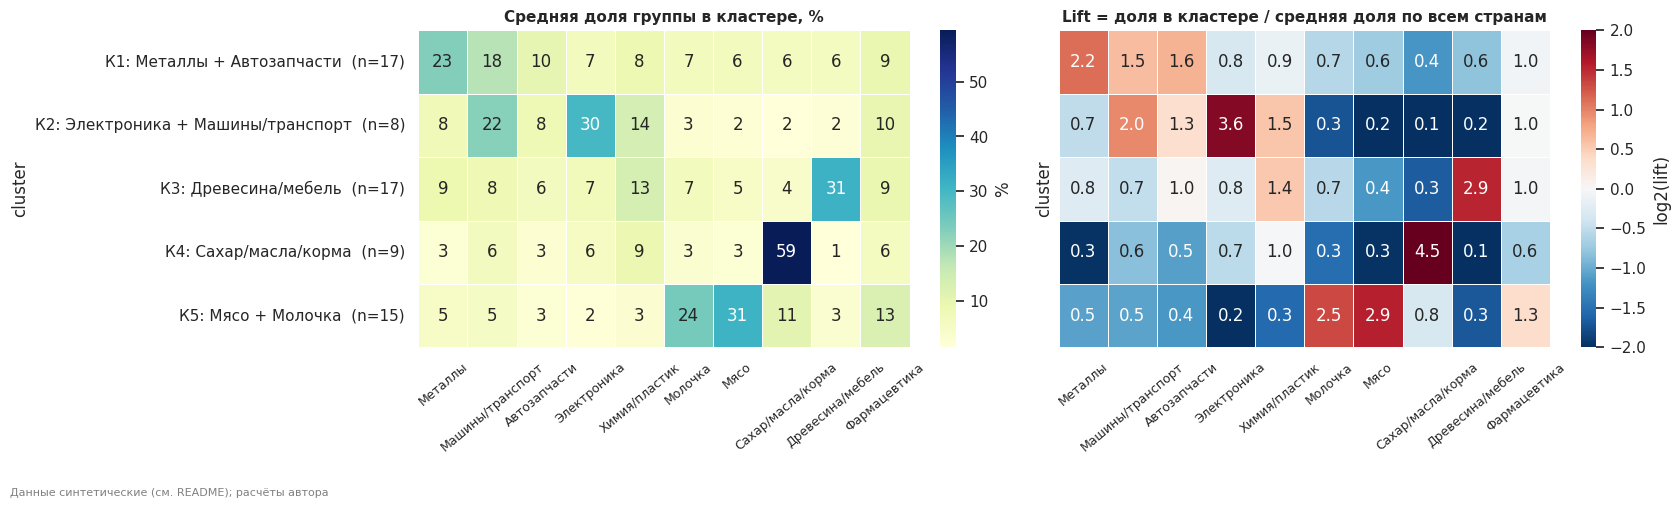

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.8))
lbl = [CL_NAME[c] + f"  (n={int((LAB == c).sum())})" for c in range(K)]
sns.heatmap(mean_.rename(columns=lambda c: SHORT[inv[c]]), annot=True, fmt=".0f", cmap="YlGnBu", ax=axes[0], yticklabels=lbl,
            cbar_kws={"label": "%"}, linewidths=0.5, linecolor="white")
axes[0].set_title("Средняя доля группы в кластере, %")
sns.heatmap(np.log2(lift).rename(columns=lambda c: SHORT[inv[c]]), annot=lift.rename(columns=lambda c: SHORT[inv[c]]).round(1), fmt="", cmap="RdBu_r",
            center=0, vmin=-2, vmax=2, ax=axes[1], yticklabels=False, cbar_kws={"label": "log2(lift)"}, linewidths=0.5, linecolor="white")
axes[1].set_title("Lift = доля в кластере / средняя доля по всем странам")
for ax in axes:
    ax.tick_params(axis="x", rotation=40, labelsize=9)
fig.text(0.01, -0.05, SRC, fontsize=8, color="grey")
fig.tight_layout()
save(fig, "fig04_cluster_profiles")

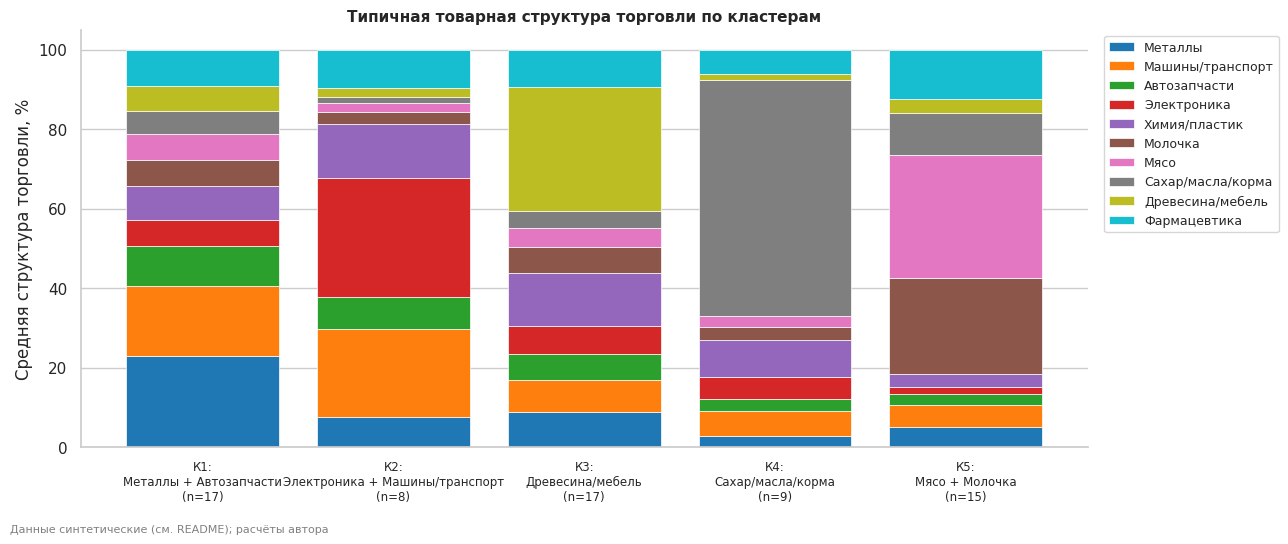

In [16]:
fig, ax = plt.subplots(figsize=(13, 5.3))
bottom = np.zeros(K)
gpal = sns.color_palette("tab10", len(vcols))
for g, col in zip(vcols, gpal):
    ax.bar(range(K), mean_[g].values, bottom=bottom, color=col, label=SHORT[inv[g]], edgecolor="white", lw=0.5)
    bottom += mean_[g].values
ax.set_xticks(range(K), [CL_NAME[c].replace(": ", ":\n") + f"\n(n={int((LAB == c).sum())})" for c in range(K)], fontsize=8.5)
ax.set_ylabel("Средняя структура торговли, %")
ax.set_title("Типичная товарная структура торговли по кластерам")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
ax.grid(axis="x", visible=False)
fig.text(0.01, -0.02, SRC, fontsize=8, color="grey")
fig.tight_layout()
save(fig, "fig05_cluster_composition")

## Шаг 8. Визуализация результата
### 8.1. Тепловая карта матрицы вместе с дендрограммой
Строки упорядочены по дендрограмме; цвет — Z-оценка (красный — доля выше средней по выборке). Цветная полоса слева — кластер.

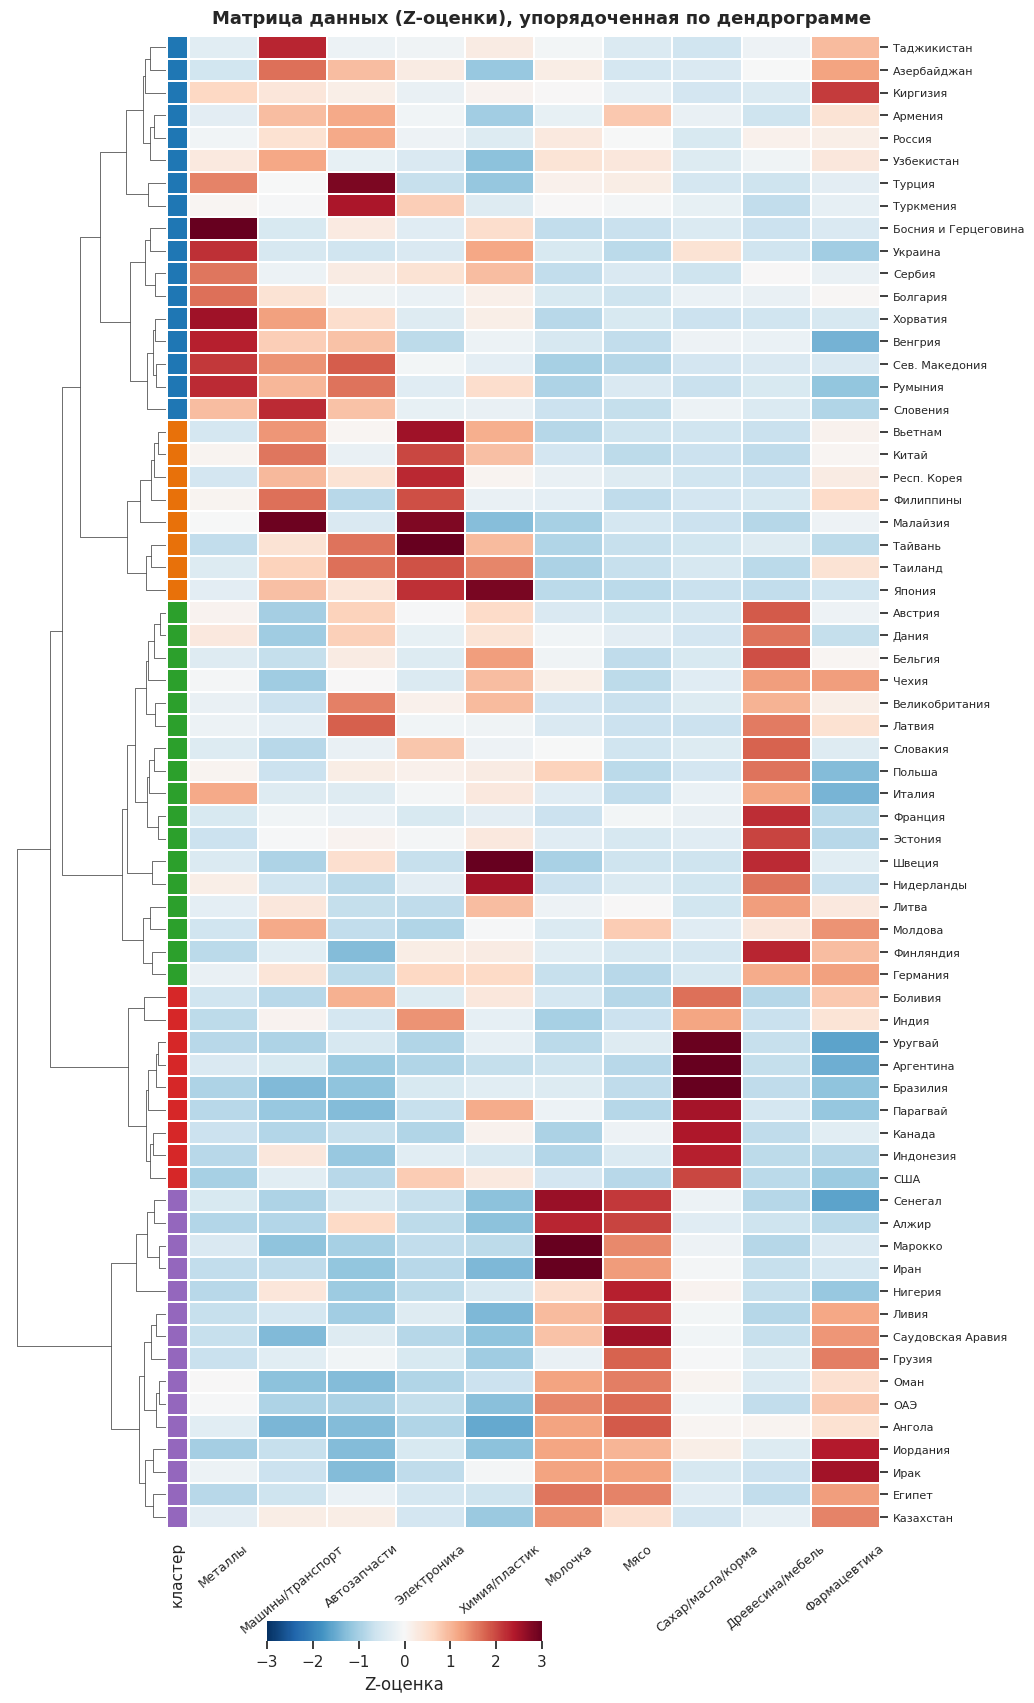

In [17]:
rc = pd.Series([PALETTE[c] for c in LAB], index=names, name="кластер")
cg = sns.clustermap(pd.DataFrame(Z, index=names, columns=[SHORT[inv[c]] for c in vcols]), row_linkage=L, col_cluster=False, row_colors=rc,
                    cmap="RdBu_r", center=0, vmin=-3, vmax=3, figsize=(11, 17), yticklabels=True, linewidths=0.2, linecolor="white",
                    cbar_pos=(0.25, 0.045, 0.25, 0.012), cbar_kws={"label": "Z-оценка", "orientation": "horizontal"},
                    dendrogram_ratio=(0.18, 0.0), colors_ratio=0.025)
for a_ in (cg.ax_heatmap, cg.ax_row_dendrogram, cg.ax_row_colors):
    a_.invert_yaxis()  # К1 сверху, как в нумерации
cg.ax_heatmap.tick_params(axis="y", labelsize=8)
cg.ax_heatmap.tick_params(axis="x", labelsize=9, rotation=40)
cg.figure.suptitle("Матрица данных (Z-оценки), упорядоченная по дендрограмме", y=1.005, fontsize=13, fontweight="bold")
cg.figure.savefig(FIG / "fig06_matrix_with_dendrogram.png")
plt.show()

**Читаем:** тепловая карта в порядке дендрограммы показывает «блочную» структуру: у каждого кластера свой яркий «красный» блок (мясо и молочка у К5, сахар у К4, древесина у К3, электроника и машины у К2, металлы у К1), вне блока цвета синие или нейтральные.
Строки К1 самые «пёстрые» — отсюда низкий силуэт.

### 8.2. Метод главных компонент (PCA): страны и вклад групп

Объяснённая дисперсия PC1..PC4: [32.2 17.8 14.5 12.7] | PC1+PC2: 50.0 %


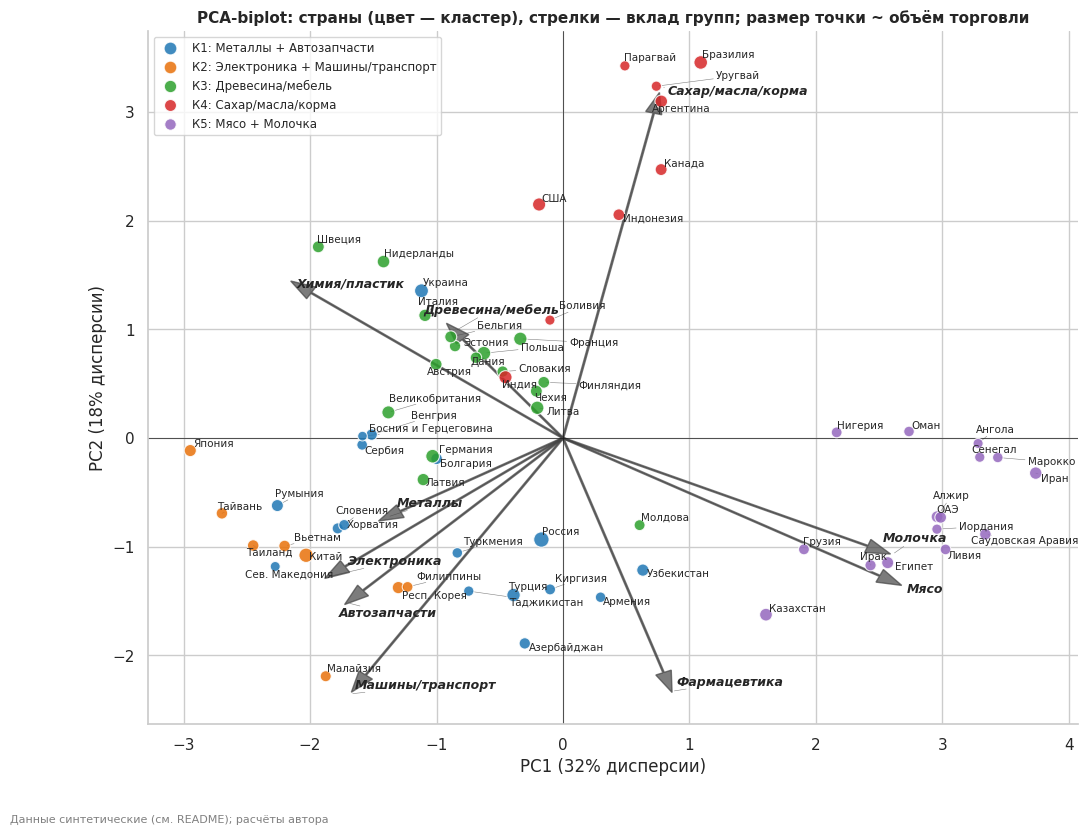


Нагрузки (Component Matrix):
                     PC1   PC2   PC3
Металлы           -0.25 -0.13  0.04
Машины/транспорт  -0.30 -0.42 -0.35
Автозапчасти      -0.30 -0.27  0.08
Электроника       -0.33 -0.23 -0.26
Химия/пластик     -0.38  0.26  0.26
Молочка            0.46 -0.19  0.14
Мясо               0.48 -0.24  0.05
Сахар/масла/корма  0.14  0.57 -0.45
Древесина/мебель  -0.15  0.17  0.69
Фармацевтика       0.15 -0.41  0.17


In [18]:
pca = PCA(n_components=min(10, Z.shape[1])).fit(Z)
Pc = pca.transform(Z)
ev = pca.explained_variance_ratio_
print("Объяснённая дисперсия PC1..PC4:", (ev[:4] * 100).round(1), "| PC1+PC2:", (ev[:2].sum() * 100).round(1), "%")
fig, ax = plt.subplots(figsize=(12, 9))
for c in range(K):
    m_ = LAB == c
    ax.scatter(Pc[m_, 0], Pc[m_, 1], s=40 + 30 * np.log10(DV["Volume"].to_numpy()[m_] + 1), color=PALETTE[c], alpha=0.85,
               edgecolor="white", lw=0.8, label=CL_NAME[c], zorder=3)
texts = [ax.text(Pc[i, 0], Pc[i, 1], names[i], fontsize=7.5) for i in range(n)]
sc = 0.8 * np.abs(Pc[:, :2]).max() / np.abs(pca.components_[:2]).max()
for j, g in enumerate(vcols):
    ax.arrow(0, 0, pca.components_[0, j] * sc, pca.components_[1, j] * sc, color="#444", alpha=0.7, width=0.012, head_width=0.13, zorder=2)
    texts.append(ax.text(pca.components_[0, j] * sc * 1.08, pca.components_[1, j] * sc * 1.08, SHORT[inv[g]], fontsize=9, fontweight="bold", style="italic"))
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="grey", lw=0.4), expand=(1.1, 1.3))
ax.axhline(0, color="k", lw=0.5)
ax.axvline(0, color="k", lw=0.5)
ax.set_xlabel(f"PC1 ({ev[0]:.0%} дисперсии)")
ax.set_ylabel(f"PC2 ({ev[1]:.0%} дисперсии)")
ax.set_title("PCA-biplot: страны (цвет — кластер), стрелки — вклад групп; размер точки ~ объём торговли")
ax.legend(fontsize=8.5, loc="best")
fig.text(0.01, 0.0, SRC, fontsize=8, color="grey")
save(fig, "fig07_pca_biplot")
load_df = pd.DataFrame(pca.components_[:3].T, index=[SHORT[inv[c]] for c in vcols], columns=["PC1", "PC2", "PC3"]).round(2)
print("\nНагрузки (Component Matrix):\n", load_df.to_string())

**Читаем (PCA):** первые две компоненты объясняют 50,0% дисперсии (PC1 32,2%, PC2 17,8%).
**PC1** — ось «продовольствие против промышленности»: положительные нагрузки у мяса (0,48) и молочки (0,46), отрицательные у химии (−0,38), электроники (−0,33), машин и автозапчастей (по −0,30).
**PC2** — «агросырьё против машин и фармацевтики»: сахар/масла/корма +0,57, машины −0,42, фармацевтика −0,41.
На плоскости чётко обособлены К4 («агросырьё», вверху) и К5 («мясо и молочка», справа); К2 и К3 заметны, но частично пересекаются с К1, который лежит ближе к центру и перекрывается с соседями.

### 8.3. Географическая карта

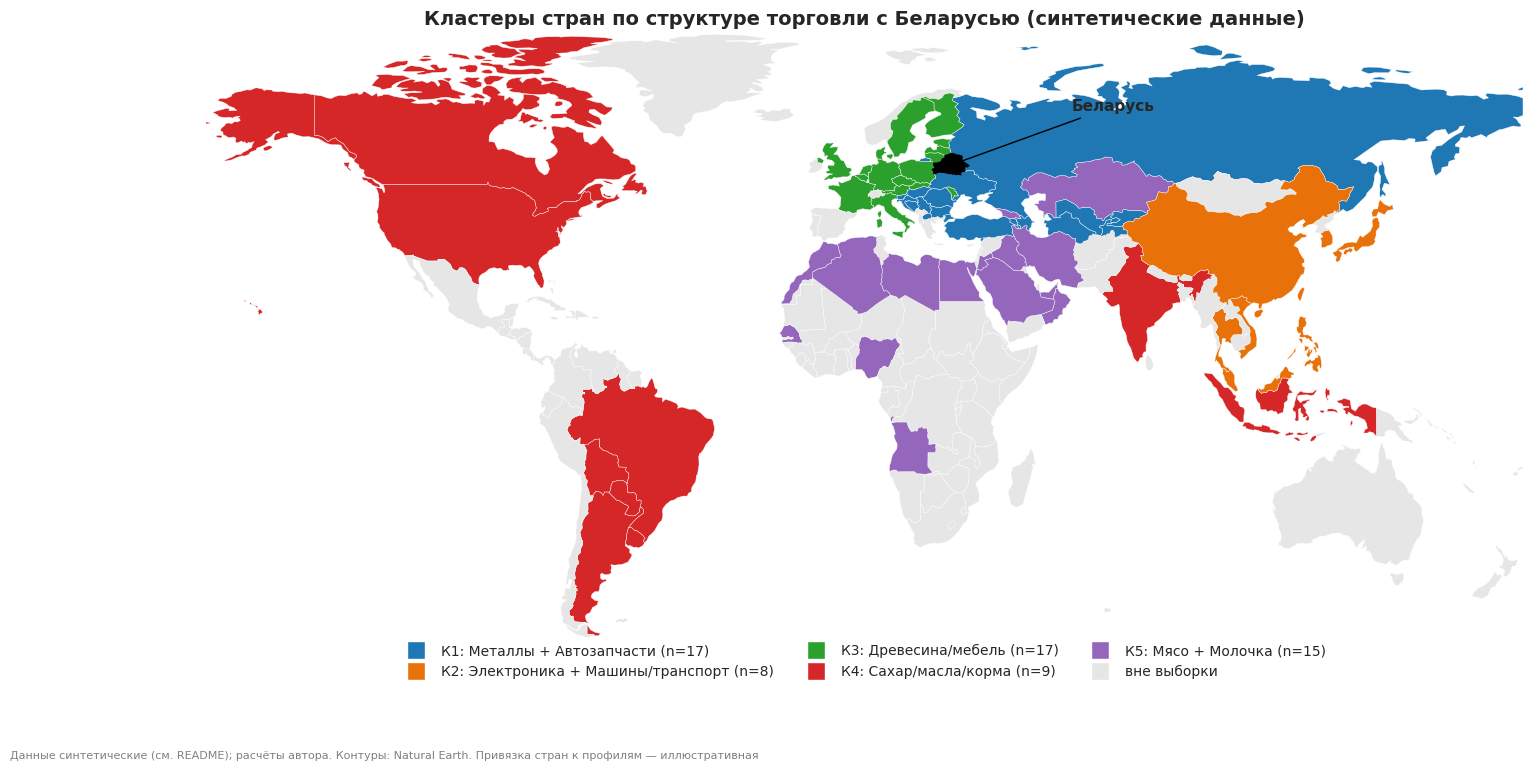

In [19]:
meta, _, geom, fields = pgraw.read(str(DATA / "geo" / "naturalearth_lowres.shp"))
fd = dict(zip(meta["fields"], fields))
world = pd.DataFrame({"iso3": fd["iso_a3"], "name": fd["name"], "geometry": shapely.from_wkb(geom)})
world = world[world["name"] != "Antarctica"].reset_index(drop=True)


def polys(g):
    return list(g.geoms) if g.geom_type == "MultiPolygon" else [g]


cl_by_iso = dict(zip(iso, LAB))
patches, fc = [], []
for _, r in world.iterrows():
    for pg in polys(r.geometry):
        if r.iso3 == "FRA" and pg.centroid.x < -20:  # заморские департаменты не относим к метрополии
            continue
        patches.append(Polygon(np.asarray(pg.exterior.coords), closed=True))
        fc.append(PALETTE[cl_by_iso[r.iso3]] if r.iso3 in cl_by_iso else "#e6e6e6")
fig, ax = plt.subplots(figsize=(17, 8.5))
ax.add_collection(PatchCollection(patches, facecolor=fc, edgecolor="white", linewidth=0.3))
for _, r in world[world.iso3 == "BLR"].iterrows():
    for pg in polys(r.geometry):
        ax.add_patch(Polygon(np.asarray(pg.exterior.coords), closed=True, facecolor="black", edgecolor="black", lw=1.2, zorder=5))
ax.annotate("Беларусь", xy=(28, 53.5), xytext=(60, 66), fontsize=11, fontweight="bold", arrowprops=dict(arrowstyle="-", color="black"), zorder=6)
ax.set_xlim(-170, 180)
ax.set_ylim(-57, 84)
ax.set_aspect(1.15)
ax.axis("off")
ax.legend(handles=[Line2D([0], [0], marker="s", color="w", markerfacecolor=PALETTE[c], markersize=13, label=CL_NAME[c] + f" (n={int((LAB == c).sum())})") for c in range(K)]
          + [Line2D([0], [0], marker="s", color="w", markerfacecolor="#e6e6e6", markersize=13, label="вне выборки")],
          loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=3, fontsize=10, frameon=False)
ax.set_title("Кластеры стран по структуре торговли с Беларусью (синтетические данные)", fontsize=14, fontweight="bold")
fig.text(0.01, 0.0, SRC + ". Контуры: Natural Earth. Привязка стран к профилям — иллюстративная", fontsize=8, color="grey")
save(fig, "fig08_world_map")

mp = pd.DataFrame({"iso3": iso, "country": names, "cluster": LAB})
mp["Кластер"] = mp["cluster"].map(CL_NAME)
mp["Топ-3 группы"] = [", ".join(f"{SHORT[inv[g]]} {DV.loc[i, g]:.0f}%" for g in DV.loc[i, vcols].sort_values(ascending=False).index[:3]) for i in range(n)]
figp = px.choropleth(mp, locations="iso3", color="Кластер", hover_name="country", hover_data={"iso3": False, "Топ-3 группы": True, "Кластер": True},
                     color_discrete_sequence=PALETTE, category_orders={"Кластер": [CL_NAME[c] for c in range(K)]},
                     title="Кластеры стран по структуре торговли (синтетические данные)")
figp.update_geos(showcountries=True, countrycolor="white", showframe=False, projection_type="natural earth")
figp.update_layout(margin=dict(l=0, r=0, t=50, b=0), legend_title_text="")
figp.write_html(str(FIG / "map_clusters_interactive.html"), include_plotlyjs="cdn")

**Читаем (карта):** при заданных допущениях сегменты разделяются на макрорегионы: Европа (К3), Азия (К2), Америка и Индонезия (К4), Ближний Восток и Северная Африка (К5), «пояс» ЕАЭС/СНГ, Турции и Балкан (К1).
Карта иллюстрирует, как выглядел бы результат при таких профилях; страны привязаны к профилям по допущению автора, а не по данным.

## Шаг 9. Проверка качества и устойчивости
(а) силуэт по странам, (б) **K-Means** с начальными центрами из иерархического решения (в SPSS — Quick Cluster с `/INITIAL`; проверяет, не «застряло» ли разбиение),
(в) устойчивость на бутстреп-подвыборках, (г) чувствительность к преобразованию (корень из долей, Hellinger), (д) соседние решения 4 и 6 кластеров.

Средний силуэт при k = 5: 0.347
По кластерам: {'К1': 0.18, 'К2': 0.4, 'К3': 0.34, 'К4': 0.46, 'К5': 0.44}
Страны на границе кластеров (силуэт < 0,1):
     country  cluster  silhouette
Таджикистан        1       -0.00
    Молдова        3        0.01
      Индия        4        0.06
     Сербия        1        0.07
     Россия        1        0.07
Азербайджан        1        0.08
 Узбекистан        1        0.08
   Киргизия        1        0.09

K-Means (старт от центров Уорда): ARI с иерархическим = 1.000; сменили кластер 0 из 66


Бутстреп (300 подвыборок по 80%): ARI = 0.84 (5–95%: 0.65–1.00)
Ward на √долях (Hellinger): ARI с основным = 0.956

Соседние решения:
  k  ARI_vs_main  silhouette                sizes
 4        0.826       0.313      [25, 17, 15, 9]
 5        1.000       0.347   [17, 17, 15, 9, 8]
 6        0.891       0.337 [17, 15, 9, 9, 8, 8]

Как 5 кластеров дробятся на 6 (строки — 5 кластеров, столбцы — 6):
k=6  1   2   3  4  5  6
k=5                    
1    8   0   0  0  0  9
2    0   0   0  8  0  0
3    0   0  17  0  0  0
4    0   0   0  0  9  0
5    0  15   0  0  0  0

При k=6 распадается К1 (К1: Металлы + Автозапчасти):
  подкластер из 8 стран; главные группы: Машины/транспорт 18%, Фармацевтика 12%, Металлы 12%
  состав: Азербайджан, Армения, Киргизия, Россия, Таджикистан, Туркмения, Турция, Узбекистан
  подкластер из 9 стран; главные группы: Металлы 33%, Машины/транспорт 17%, Химия/пластик 11%
  состав: Болгария, Босния и Герцеговина, Венгрия, Румыния, Сев. Македония, Сербия, Словения, Украи

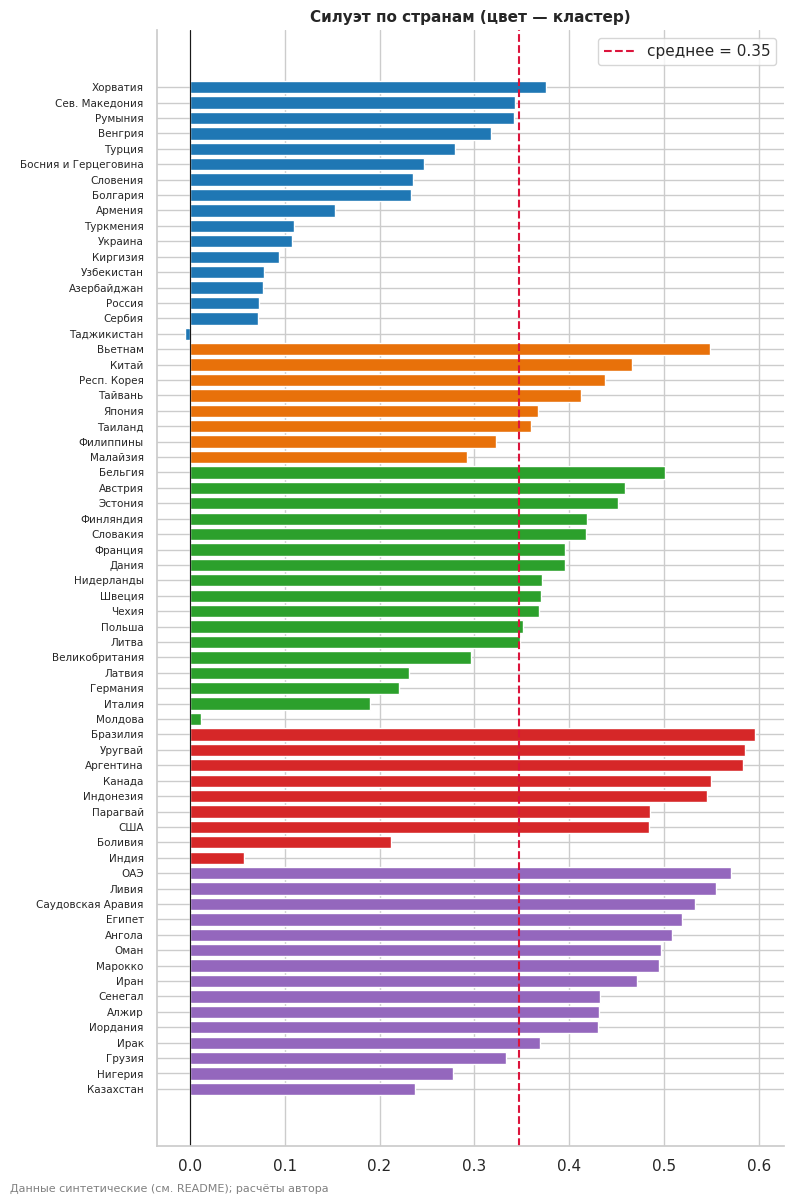


[Диагностика, только синтетика] ARI с заложенными архетипами: 0.767
кластер   1  2   3  4   5
архетип                  
A         7  0   1  0   2
B         0  0  16  0   0
C         0  0   0  0  13
D         0  8   0  1   0
E         0  0   0  8   0
F        10  0   0  0   0


In [20]:
sil = silhouette_samples(Z, LAB)
print(f"Средний силуэт при k = {K}: {sil.mean():.3f}")
print("По кластерам:", {f"К{c + 1}": round(float(sil[LAB == c].mean()), 2) for c in range(K)})
weak = pd.DataFrame({"country": names, "cluster": LAB + 1, "silhouette": sil}).sort_values("silhouette")
print("Страны на границе кластеров (силуэт < 0,1):\n", weak[weak.silhouette < 0.1].round(2).to_string(index=False))

km = KMeans(K, init=cent, n_init=1, random_state=SEED).fit(Z)
moved = int((km.labels_ != LAB).sum())
print(f"\nK-Means (старт от центров Уорда): ARI с иерархическим = {adjusted_rand_score(LAB, km.labels_):.3f}; сменили кластер {moved} из {n}")

rng = np.random.default_rng(SEED)
bt = []
for _ in range(300):
    idx = np.sort(rng.choice(n, int(0.8 * n), replace=False))
    zz = (DV[vcols].iloc[idx] - DV[vcols].iloc[idx].mean()) / DV[vcols].iloc[idx].std(ddof=1)
    l2 = cut_tree(linkage(zz.to_numpy(), "ward"), K).ravel()
    bt.append(adjusted_rand_score(LAB[idx], l2))
print(f"Бутстреп (300 подвыборок по 80%): ARI = {np.mean(bt):.2f} (5–95%: {np.percentile(bt, 5):.2f}–{np.percentile(bt, 95):.2f})")

H = np.sqrt(DV[vcols].to_numpy() / 100)
Hz = (H - H.mean(axis=0)) / H.std(axis=0, ddof=1)
lab_h = cut_tree(linkage(Hz, "ward"), K).ravel()
print(f"Ward на √долях (Hellinger): ARI с основным = {adjusted_rand_score(LAB, lab_h):.3f}")
rows = []
for k in (4, 5, 6):
    l_k = cut_tree(L, k).ravel()
    rows.append(dict(k=k, ARI_vs_main=adjusted_rand_score(LAB, l_k), silhouette=silhouette_score(Z, l_k), sizes=sorted(np.bincount(l_k).tolist(), reverse=True)))
print("\nСоседние решения:\n", pd.DataFrame(rows).round(3).to_string(index=False))
l6 = cut_tree(L, 6).ravel()
print("\nКак 5 кластеров дробятся на 6 (строки — 5 кластеров, столбцы — 6):")
print(pd.crosstab(pd.Series(LAB + 1, name="k=5"), pd.Series(l6 + 1, name="k=6")).to_string())

ct = pd.crosstab(LAB, l6)
split_c = int(ct.index[(ct > 0).sum(axis=1) > 1][0])  # кластер k=5, который при k=6 распадается
print(f"\nПри k=6 распадается К{split_c + 1} ({CL_NAME[split_c]}):")
sub = [c for c in ct.columns if ct.loc[split_c, c] > 0]
for c in sub:
    msk = l6 == c
    top = DV.loc[msk, vcols].mean().sort_values(ascending=False)
    print(f"  подкластер из {int(msk.sum())} стран; главные группы: " + ", ".join(f"{SHORT[inv[g]]} {top[g]:.0f}%" for g in top.index[:3]))
    print("  состав:", ", ".join(sorted(names[msk])))

fig, ax = plt.subplots(figsize=(8, 12))
o = weak.sort_values(["cluster", "silhouette"], ascending=[False, True]).reset_index(drop=True)
ax.barh(o["country"], o["silhouette"], color=[PALETTE[c - 1] for c in o["cluster"]])
ax.axvline(0, color="k", lw=0.8)
ax.axvline(sil.mean(), color="crimson", ls="--", label=f"среднее = {sil.mean():.2f}")
ax.tick_params(axis="y", labelsize=7.5)
ax.set_title("Силуэт по странам (цвет — кластер)")
ax.legend()
fig.text(0.01, 0.0, SRC, fontsize=8, color="grey")
fig.tight_layout()
save(fig, "fig09_silhouette")

if HAS_TRUTH:
    truth = raw["true_archetype"].to_numpy()
    print(f"\n[Диагностика, только синтетика] ARI с заложенными архетипами: {adjusted_rand_score(truth, LAB):.3f}")
    print(pd.crosstab(pd.Series(truth, name="архетип"), pd.Series(LAB + 1, name="кластер")).to_string())

**Читаем (проверка):**
- **Силуэт 0,347** (К4 0,46, К5 0,44, К2 0,40, К3 0,34, К1 0,18): структура выражена умеренно, К1 — слабое звено. Страны на границе (силуэт < 0,1): Таджикистан, Молдова, Индия, Сербия, Россия, Азербайджан, Узбекистан, Киргизия.
- **K-Means** с начальными центрами из решения Уорда не сдвинул ни одну страну (ARI = 1,00): разбиение — устойчивый локальный оптимум.
- **Бутстреп** (300 подвыборок по 80%): среднее ARI 0,84 (5–95%: 0,65–1,00) — умеренная устойчивость, ниже для пограничных стран К1.
- **Другое преобразование** (корень из долей, Hellinger): ARI с основным 0,956.
- **Соседние решения:** при k = 4 ARI с основным 0,83 (силуэт 0,313), при k = 6 — 0,89 (силуэт 0,337). Шестой кластер получается делением К1 на «ЕАЭС/СНГ и Турция» (8 стран: машины 18%, фармацевтика 12%, металлы 12%) и «Балканы и Украина» (9 стран: металлы 33%).
- **Диагностика на синтетике** (эталон не использовался при выборе k): ARI = 0,77. Пять кластеров восстанавливают пять из шести заложенных архетипов; К1 объединяет два (ЕАЭС/СНГ и «металл и транспорт»).

## Шаг 10. Сохранение результатов, файлы для SPSS

In [21]:
out = pd.DataFrame({"Case": np.arange(1, n + 1), "Country": names, "ISO3": iso, "Cluster": LAB + 1, "Silhouette": sil}).merge(
    DV[["Case"] + vcols], on="Case")
out.to_csv(RES / "11_country_clusters.csv", index=False, encoding="utf-8-sig")
DV_sav = DV.copy()
DV_sav["Cluster5"] = LAB + 1
pyreadstat.write_sav(DV_sav, str(DATA / "trade_shares_with_clusters.sav"),
                     column_labels=labels + [f"Кластер (Ward, k={K}), результат Python"],
                     variable_measure={c: ("scale" if c not in ("Country", "ISO3", "Cluster5") else "nominal") for c in DV_sav.columns})
zv = " ".join(f"Z{v}" for v in vcols)
sps = f"""* Воспроизведение анализа в SPSS (синтаксис). Файл trade_shares.sav лежит в папке data/. Измените путь в GET FILE.
* ВНИМАНИЕ: синтаксис составлен по стандартным командам SPSS, но в среде SPSS не запускался; цифры сверяйте с results/05_agglomeration_schedule.csv.
GET FILE='data/trade_shares.sav'.
* 1) Z-оценки (создаст переменные Z + имя).
DESCRIPTIVES VARIABLES={' '.join(vcols)}
  /SAVE.
* 2) Иерархический кластерный анализ: метод Уорда, квадрат евклидова расстояния.
CLUSTER {zv}
  /METHOD WARD
  /MEASURE=SEUCLID
  /ID=Country
  /PRINT SCHEDULE CLUSTER(2,8)
  /PLOT DENDROGRAM VICICLE
  /SAVE CLUSTER({K}).
* 3) Профиль кластеров: средние по переменным и ANOVA.
ONEWAY {' '.join(vcols)} BY CLU{K}_1
  /STATISTICS DESCRIPTIVES
  /MISSING ANALYSIS.
* 4) Проверка K-Means на {K} кластерах (начальные центры SPSS выбирает сам; в Python-версии стартовали от центров Уорда).
QUICK CLUSTER {zv}
  /CRITERIA=CLUSTER({K}) MXITER(20) CONVERGE(0)
  /METHOD=KMEANS(NOUPDATE)
  /PRINT INITIAL ANOVA CLUSTER DISTAN.
"""
(SPSS / "cluster_analysis.sps").write_text(sps, encoding="utf-8")
print("Файлы:", sorted(p_.name for p_ in RES.iterdir()))
print("SPSS:", sorted(p_.name for p_ in SPSS.iterdir()), "| data:", sorted(p_.name for p_ in DATA.iterdir() if p_.is_file()))

Файлы: ['01_data_view.csv', '02_variable_view.csv', '03_descriptives.csv', '04_proximity_matrix_sqeuclid.csv', '05_agglomeration_schedule.csv', '06_cut_validation.csv', '07_cluster_membership_2_to_8.csv', '08_cluster_profiles.csv', '09_cluster_means_percent.csv', '10_anova_by_variable.csv', '11_country_clusters.csv']
SPSS: ['cluster_analysis.sps'] | data: ['trade_shares.csv', 'trade_shares.sav', 'trade_shares_with_clusters.sav']


## Итоговые выводы
1. **Данные.** Матрица 66 стран × 10 переменных (доли групп, %), без пропусков; корреляции умеренные (max |r| = 0,76), выбросы (7 наблюдений) — реальная специализация, не ошибки.
2. **Число кластеров.** По таблице агломерации наибольший скачок стоимости объединения — при переходе 5 → 4 (×1,70); силуэт и индекс Калински–Харабаза максимальны при том же k = 5. Выбрано **5 кластеров**; дендрограмма показывает иерархию: две «продовольственные» ветви отделяются последними.
3. **Профили.** Пять понятных сегментов: «Металлы и автозапчасти» (17), «Азия: электроника и машины» (8), «Европа: древесина и мебель» (17), «Агросырьё» (9), «Импортёры мяса и молочки» (15). Четыре из пяти выражены ярко (lift 2,2–4,5), К1 — «размытый».
4. **Визуализация.** PCA сводит различия к двум осям (продовольствие ↔ промышленность; агросырьё ↔ машины/фармацевтика), карта показывает региональный характер сегментов.
5. **Надёжность.** Разбиение устойчиво по методу (K-Means, другое преобразование: ARI 0,96–1,00), умеренно устойчиво к подвыборкам (0,84). Самое слабое место — К1, который при k = 6 естественно делится на два.
6. **Ограничение.** Данные синтетические; выводы описывают метод, а не реальную торговлю. На реальных данных процедура запускается без изменений (`TRADE_CSV`).